# Trabalho de Ciência de Dados — Análise Descritiva
## Conjunto de dados: Automóveis (UCI Automobile Data Set)

**Objetivo:** descrever a base, investigar inconsistências, calcular estatísticas, formular perguntas com filtros booleanos, avaliar correlações e associações e produzir os gráficos solicitados.


In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import PowerTransformer

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

NOMES_COLUNAS = [
    "simbolo_risco", "perdas_normalizadas", "marca", "tipo_combustivel",
    "aspiracao", "numero_portas", "estilo_carroceria", "tracao_rodas",
    "local_motor", "entre_eixos", "comprimento", "largura", "altura",
    "peso_veiculo", "tipo_motor", "numero_cilindros", "tamanho_motor",
    "sistema_combustivel", "diametro_cilindro", "curso_pistao",
    "taxa_compressao", "potencia", "rpm_maximo", "consumo_cidade",
    "consumo_estrada", "preco"
]

database = pd.read_csv(
    "imports-85.data",
    header=None,
    names=NOMES_COLUNAS,
    na_values="?",
    skipinitialspace=True
)

# Colunas que devem ser numéricas no conjunto original.
COLUNAS_NUMERICAS_ESPERADAS = [
    "simbolo_risco", "perdas_normalizadas", "entre_eixos", "comprimento",
    "largura", "altura", "peso_veiculo", "numero_cilindros",
    "tamanho_motor", "diametro_cilindro", "curso_pistao",
    "taxa_compressao", "potencia", "rpm_maximo", "consumo_cidade",
    "consumo_estrada", "preco"
]
for coluna in COLUNAS_NUMERICAS_ESPERADAS:
    database[coluna] = pd.to_numeric(database[coluna], errors="coerce")

print("Base carregada com sucesso.")
print(f"Registros: {database.shape[0]}")
print(f"Atributos: {database.shape[1]}")
display(database.head())

Base carregada com sucesso.
Registros: 205
Atributos: 26


,simbolo_risco,perdas_normalizadas,marca,tipo_combustivel,aspiracao,numero_portas,estilo_carroceria,tracao_rodas,local_motor,entre_eixos,comprimento,largura,altura,peso_veiculo,tipo_motor,numero_cilindros,tamanho_motor,sistema_combustivel,diametro_cilindro,curso_pistao,taxa_compressao,potencia,rpm_maximo,consumo_cidade,consumo_estrada,preco
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,NaN,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,NaN,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,NaN,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,NaN,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,NaN,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0


## 1. Descrição do conjunto de dados

A base descreve automóveis por características técnicas, dimensões, desempenho, tipo de combustível, carroceria, marca e preço. O atributo **`preco`** pode ser tratado como variável de saída caso o objetivo seja estudar ou estimar o preço do veículo.

O conjunto original tem 205 registros e 26 atributos. A célula abaixo confirma as dimensões efetivamente carregadas, evitando depender apenas de valores informados previamente.

In [4]:
print(f"Quantidade de exemplos (linhas): {database.shape[0]}")
print(f"Quantidade de atributos (colunas): {database.shape[1]}")
print("\nNomes dos atributos:")
for coluna in database.columns:
    print(f"- {coluna}")

print("\nTipos de dados:")
display(database.dtypes.rename("tipo_de_dado").to_frame())

print("\nPossível atributo de saída: preco")
print("Justificativa: preço é uma variável numérica que pode ser explicada por características do automóvel.")

Quantidade de exemplos (linhas): 205
Quantidade de atributos (colunas): 26

Nomes dos atributos:
- simbolo_risco
- perdas_normalizadas
- marca
- tipo_combustivel
- aspiracao
- numero_portas
- estilo_carroceria
- tracao_rodas
- local_motor
- entre_eixos
- comprimento
- largura
- altura
- peso_veiculo
- tipo_motor
- numero_cilindros
- tamanho_motor
- sistema_combustivel
- diametro_cilindro
- curso_pistao
- taxa_compressao
- potencia
- rpm_maximo
- consumo_cidade
- consumo_estrada
- preco

Tipos de dados:


,tipo_de_dado
simbolo_risco,int64
perdas_normalizadas,float64
marca,str
tipo_combustivel,str
aspiracao,str
numero_portas,str
estilo_carroceria,str
tracao_rodas,str
local_motor,str
entre_eixos,float64



Possível atributo de saída: preco
Justificativa: preço é uma variável numérica que pode ser explicada por características do automóvel.


### Verificação de inconsistências e valores ausentes

Os valores `?` do arquivo original foram convertidos para `NaN` durante a leitura. A análise abaixo mostra os valores ausentes por coluna e procura duplicatas. Valores ausentes não serão removidos automaticamente: a decisão depende da quantidade e da importância da variável.

In [5]:
ausentes = database.isna().sum().sort_values(ascending=False)
percentual_ausente = (database.isna().mean() * 100).sort_values(ascending=False)
resumo_ausentes = pd.DataFrame({
    "quantidade_ausente": ausentes,
    "percentual_ausente": percentual_ausente.round(2)
})
display(resumo_ausentes[resumo_ausentes["quantidade_ausente"] > 0])

print("Linhas duplicadas:", database.duplicated().sum())
print("\nResumo de valores únicos por atributo:")
display(database.nunique(dropna=True).rename("valores_unicos").to_frame())

print("\nAjustes realizados:")
print("- O arquivo foi lido sem cabeçalho e recebeu nomes de colunas.")
print("- O símbolo '?' foi interpretado como valor ausente (NaN).")
print("- Colunas numéricas foram convertidas para tipos numéricos; valores inválidos viraram NaN.")
print("- Os valores ausentes foram mantidos nesta etapa para não eliminar observações sem justificativa.")

,quantidade_ausente,percentual_ausente
numero_cilindros,205,100.00
perdas_normalizadas,41,20.00
diametro_cilindro,4,1.95
curso_pistao,4,1.95
preco,4,1.95
potencia,2,0.98
rpm_maximo,2,0.98
numero_portas,2,0.98


Linhas duplicadas: 0

Resumo de valores únicos por atributo:


,valores_unicos
simbolo_risco,6
perdas_normalizadas,51
marca,22
tipo_combustivel,2
aspiracao,2
numero_portas,2
estilo_carroceria,5
tracao_rodas,3
local_motor,2
entre_eixos,53



Ajustes realizados:
- O arquivo foi lido sem cabeçalho e recebeu nomes de colunas.
- O símbolo '?' foi interpretado como valor ausente (NaN).
- Colunas numéricas foram convertidas para tipos numéricos; valores inválidos viraram NaN.
- Os valores ausentes foram mantidos nesta etapa para não eliminar observações sem justificativa.


## 2. Estatísticas descritivas

Para os atributos numéricos, serão apresentados contagem válida, média, desvio padrão, mínimo, quartis, mediana, máximo e variância. Para os atributos categóricos, serão apresentados frequência absoluta, frequência relativa e moda. A interpretação deve considerar que algumas variáveis possuem valores ausentes.

In [6]:
colunas_numericas = database.select_dtypes(include=np.number).columns.tolist()
colunas_categoricas = database.select_dtypes(exclude=np.number).columns.tolist()

estatisticas_numericas = database[colunas_numericas].describe().T
estatisticas_numericas["mediana"] = database[colunas_numericas].median()
estatisticas_numericas["variancia"] = database[colunas_numericas].var()
estatisticas_numericas = estatisticas_numericas[
    ["count", "mean", "std", "min", "25%", "mediana", "50%", "75%", "max", "variancia"]
]
display(estatisticas_numericas.round(2))

print("A tabela apresenta as estatísticas de todos os atributos numéricos.")
print("A mediana coincide com o percentil 50%; ambos foram mantidos para deixar o requisito explícito.")

,count,mean,std,min,25%,mediana,50%,75%,max,variancia
simbolo_risco,205.0,0.83,1.25,-2.00,0.00,1.00,1.00,2.00,3.00,1.55
perdas_normalizadas,164.0,122.00,35.44,65.00,94.00,115.00,115.00,150.00,256.00,1256.15
entre_eixos,205.0,98.76,6.02,86.60,94.50,97.00,97.00,102.40,120.90,36.26
comprimento,205.0,174.05,12.34,141.10,166.30,173.20,173.20,183.10,208.10,152.21
largura,205.0,65.91,2.15,60.30,64.10,65.50,65.50,66.90,72.30,4.60
altura,205.0,53.72,2.44,47.80,52.00,54.10,54.10,55.50,59.80,5.97
peso_veiculo,205.0,2555.57,520.68,1488.00,2145.00,2414.00,2414.00,2935.00,4066.00,271107.87
numero_cilindros,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tamanho_motor,205.0,126.91,41.64,61.00,97.00,120.00,120.00,141.00,326.00,1734.11
diametro_cilindro,201.0,3.33,0.27,2.54,3.15,3.31,3.31,3.59,3.94,0.07


A tabela apresenta as estatísticas de todos os atributos numéricos.
A mediana coincide com o percentil 50%; ambos foram mantidos para deixar o requisito explícito.


In [7]:
# Frequência absoluta, relativa e moda de todos os atributos categóricos.
for coluna in colunas_categoricas:
    print(f"\n### {coluna}")
    contagem = database[coluna].value_counts(dropna=False)
    percentual = database[coluna].value_counts(normalize=True, dropna=False) * 100
    tabela = pd.DataFrame({
        "frequencia_absoluta": contagem,
        "frequencia_relativa_percentual": percentual.round(2)
    })
    display(tabela)
    modas = database[coluna].mode(dropna=True)
    print("Moda(s):", modas.tolist() if not modas.empty else "Não disponível")


### marca


,frequencia_absoluta,frequencia_relativa_percentual
marca,,
toyota,32,15.61
nissan,18,8.78
mazda,17,8.29
honda,13,6.34
mitsubishi,13,6.34
subaru,12,5.85
volkswagen,12,5.85
peugot,11,5.37
volvo,11,5.37


Moda(s): ['toyota']

### tipo_combustivel


,frequencia_absoluta,frequencia_relativa_percentual
tipo_combustivel,,
gas,185,90.24
diesel,20,9.76


Moda(s): ['gas']

### aspiracao


...

Moda(s): ['front']

### tipo_motor


,frequencia_absoluta,frequencia_relativa_percentual
tipo_motor,,
ohc,148,72.20
ohcf,15,7.32
ohcv,13,6.34
dohc,12,5.85
l,12,5.85
rotor,4,1.95
dohcv,1,0.49


Moda(s): ['ohc']

### sistema_combustivel


,frequencia_absoluta,frequencia_relativa_percentual
sistema_combustivel,,
mpfi,94,45.85
2bbl,66,32.20
idi,20,9.76
1bbl,11,5.37
spdi,9,4.39
4bbl,3,1.46
mfi,1,0.49
spfi,1,0.49


Moda(s): ['mpfi']


### Interpretação das estatísticas

Use as tabelas acima para identificar, por exemplo, quais marcas aparecem mais, quais tipos de combustível são mais frequentes, a amplitude dos preços e a dispersão de potência, peso e consumo. Médias muito diferentes das medianas podem indicar assimetria ou presença de valores extremos. A conclusão precisa ser coerente com os valores efetivamente exibidos.

In [8]:
if "preco" in database.columns:
    print("Resumo interpretativo automático:")
    print(f"- Preço médio: {database['preco'].mean():.2f}")
    print(f"- Mediana do preço: {database['preco'].median():.2f}")
    print(f"- Preço mínimo: {database['preco'].min():.2f}")
    print(f"- Preço máximo: {database['preco'].max():.2f}")
    print(f"- Registros sem preço: {database['preco'].isna().sum()}")
    if database["preco"].mean() > database["preco"].median():
        print("- A média do preço é maior que a mediana, o que pode indicar assimetria à direita.")
    elif database["preco"].mean() < database["preco"].median():
        print("- A média do preço é menor que a mediana, o que pode indicar assimetria à esquerda.")
    else:
        print("- Média e mediana do preço são iguais ou muito próximas.")

Resumo interpretativo automático:
- Preço médio: 13207.13
- Mediana do preço: 10295.00
- Preço mínimo: 5118.00
- Preço máximo: 45400.00
- Registros sem preço: 4
- A média do preço é maior que a mediana, o que pode indicar assimetria à direita.


## 3. Oito perguntas usando filtros booleanos

As perguntas abaixo investigam relações potencialmente úteis. Cada consulta exibe os resultados e a quantidade de veículos encontrados. As categorias de `numero_portas` são textos (`two` e `four`) na base original; por isso, não devem ser comparadas com números inteiros ou strings `'2'` e `'4'`.

In [9]:
# Para as consultas, usamos uma cópia da base. Os filtros numéricos ignoram NaN automaticamente.
def mostrar_consulta(titulo, resultado, colunas=None):
    print(f"\n{titulo}")
    print(f"Quantidade de veículos encontrados: {len(resultado)}")
    if colunas:
        display(resultado[colunas].head(15))
    else:
        display(resultado.head(15))

# 1. Veículos com potência acima da média e preço abaixo da média.
potencia_media = database["potencia"].mean()
preco_medio = database["preco"].mean()
q1 = database.loc[(database["potencia"] > potencia_media) & (database["preco"] < preco_medio)]
mostrar_consulta("1) Quais veículos combinam potência acima da média e preço abaixo da média?", q1,
                 ["marca", "potencia", "preco", "tipo_combustivel"])

# 2. Quais veículos estão no quartil superior de preço e quais combustíveis utilizam?
q3_preco = database["preco"].quantile(0.75)
q2 = database.loc[database["preco"] > q3_preco]
mostrar_consulta("2) Quais veículos estão entre os 25% mais caros?", q2,
                 ["marca", "tipo_combustivel", "estilo_carroceria", "preco"])

# 3. Veículos de duas portas com comprimento inferior à mediana.
mediana_comprimento = database["comprimento"].median()
q3 = database.loc[(database["numero_portas"] == "two") &
                  (database["comprimento"] < mediana_comprimento)]
mostrar_consulta("3) Quais veículos de duas portas são menores que a mediana de comprimento?", q3,
                 ["marca", "numero_portas", "comprimento", "preco"])

# 4. Veículos mais altos e com potência elevada.
q4 = database.loc[(database["altura"] > database["altura"].quantile(0.75)) &
                  (database["potencia"] > 120)]
mostrar_consulta("4) Quais veículos estão no quartil superior de altura e têm potência acima de 120?", q4,
                 ["marca", "altura", "potencia", "preco"])

# 5. Veículos de quatro portas com preço acima da mediana.
mediana_preco = database["preco"].median()
q5 = database.loc[(database["numero_portas"] == "four") &
                  (database["preco"] > mediana_preco)]
mostrar_consulta("5) Quais veículos de quatro portas custam mais que a mediana?", q5,
                 ["marca", "numero_portas", "preco", "estilo_carroceria"])

# 6. Veículos com altura no decil inferior e potência no quartil superior.
limite_altura = database["altura"].quantile(0.10)
limite_potencia = database["potencia"].quantile(0.75)
q6 = database.loc[(database["altura"] < limite_altura) &
                  (database["potencia"] > limite_potencia)]
mostrar_consulta("6) Existem veículos muito baixos e com potência no quartil superior?", q6,
                 ["marca", "altura", "potencia", "preco"])

# 7. Veículos dentro da faixa interquartil do preço.
q1_preco = database["preco"].quantile(0.25)
q3_preco = database["preco"].quantile(0.75)
q7 = database.loc[database["preco"].between(q1_preco, q3_preco, inclusive="both")]
mostrar_consulta("7) Quais veículos estão na faixa interquartil de preço?", q7,
                 ["marca", "preco", "potencia", "consumo_cidade"])

# 8. Veículos no quartil inferior de preço com consumo urbano melhor que a mediana.
q1_preco = database["preco"].quantile(0.25)
mediana_consumo = database["consumo_cidade"].median()
q8 = database.loc[(database["preco"] < q1_preco) &
                  (database["consumo_cidade"] > mediana_consumo)]
mostrar_consulta("8) Quais veículos estão entre os mais baratos e acima da mediana de consumo urbano?", q8,
                 ["marca", "preco", "consumo_cidade", "potencia"])


1) Quais veículos combinam potência acima da média e preço abaixo da média?
Quantidade de veículos encontrados: 18


,marca,potencia,preco,tipo_combustivel
29,dodge,145.0,12964.0,gas
80,mitsubishi,116.0,9959.0,gas
82,mitsubishi,145.0,12629.0,gas
87,mitsubishi,116.0,9279.0,gas
88,mitsubishi,116.0,9279.0,gas
124,plymouth,145.0,12764.0,gas
132,saab,110.0,11850.0,gas
133,saab,110.0,12170.0,gas
145,subaru,111.0,11259.0,gas
149,subaru,111.0,11694.0,gas



2) Quais veículos estão entre os 25% mais caros?
Quantidade de veículos encontrados: 50


,marca,tipo_combustivel,estilo_carroceria,preco
4,audi,gas,sedan,17450.0
6,audi,gas,sedan,17710.0
7,audi,gas,wagon,18920.0
8,audi,gas,sedan,23875.0
11,bmw,gas,sedan,16925.0
12,bmw,gas,sedan,20970.0
13,bmw,gas,sedan,21105.0
14,bmw,gas,sedan,24565.0
15,bmw,gas,sedan,30760.0
16,bmw,gas,sedan,41315.0



3) Quais veículos de duas portas são menores que a mediana de comprimento?
Quantidade de veículos encontrados: 58


...

,marca,altura,potencia,preco
29,dodge,50.2,145.0,12964.0
49,jaguar,47.8,262.0,36000.0
58,mazda,49.6,135.0,15645.0
82,mitsubishi,50.2,145.0,12629.0
83,mitsubishi,50.2,145.0,14869.0
84,mitsubishi,50.2,145.0,14489.0
104,nissan,49.7,160.0,17199.0
105,nissan,49.7,200.0,19699.0
106,nissan,49.7,160.0,18399.0
124,plymouth,50.2,145.0,12764.0



7) Quais veículos estão na faixa interquartil de preço?
Quantidade de veículos encontrados: 102


,marca,preco,potencia,consumo_cidade
0,alfa-romero,13495.0,111.0,21
1,alfa-romero,16500.0,111.0,21
2,alfa-romero,16500.0,154.0,19
3,audi,13950.0,102.0,24
5,audi,15250.0,110.0,19
10,bmw,16430.0,101.0,23
23,dodge,7957.0,102.0,24
27,dodge,8558.0,102.0,24
28,dodge,8921.0,88.0,24
29,dodge,12964.0,145.0,19



8) Quais veículos estão entre os mais baratos e acima da mediana de consumo urbano?
Quantidade de veículos encontrados: 47


,marca,preco,consumo_cidade,potencia
18,chevrolet,5151.0,47,48.0
19,chevrolet,6295.0,38,70.0
20,chevrolet,6575.0,38,70.0
21,dodge,5572.0,37,68.0
22,dodge,6377.0,31,68.0
24,dodge,6229.0,31,68.0
25,dodge,6692.0,31,68.0
26,dodge,7609.0,31,68.0
30,honda,6479.0,49,58.0
31,honda,6855.0,31,76.0


### Conclusão das consultas

As consultas permitem explorar combinações entre preço, potência, dimensões, número de portas e consumo. Elas não provam causalidade: mostram subconjuntos que podem ser comparados e investigados. Após executar, observe os tamanhos dos resultados e os atributos dos veículos retornados. Se alguma consulta não retornar registros, isso também é um resultado e deve ser relatado sem inventar uma explicação.

In [10]:
resumo_consultas = pd.DataFrame({
    "pergunta": [
        "Potência acima da média e preço abaixo da média",
        "Preço no quartil superior",
        "Duas portas e comprimento abaixo da mediana",
        "Altura no quartil superior e potência > 120",
        "Quatro portas e preço acima da mediana",
        "Altura no decil inferior e potência no quartil superior",
        "Preço na faixa interquartil",
        "Preço no quartil inferior e consumo urbano acima da mediana"
    ],
    "quantidade_encontrada": [len(q1), len(q2), len(q3), len(q4), len(q5), len(q6), len(q7), len(q8)]
})
display(resumo_consultas)

,pergunta,quantidade_encontrada
0,Potência acima da média e preço abaixo da média,18
1,Preço no quartil superior,50
2,Duas portas e comprimento abaixo da mediana,58
3,Altura no quartil superior e potência > 120,15
4,Quatro portas e preço acima da mediana,59
5,Altura no decil inferior e potência no quartil superior,12
6,Preço na faixa interquartil,102
7,Preço no quartil inferior e consumo urbano acima da mediana,47


## 4. Correlação e associação entre atributos

A correlação de Pearson avalia associação linear entre variáveis numéricas; Spearman avalia associação monotônica baseada em postos. Correlação não implica causalidade. Valores ausentes são ignorados no cálculo por pares.

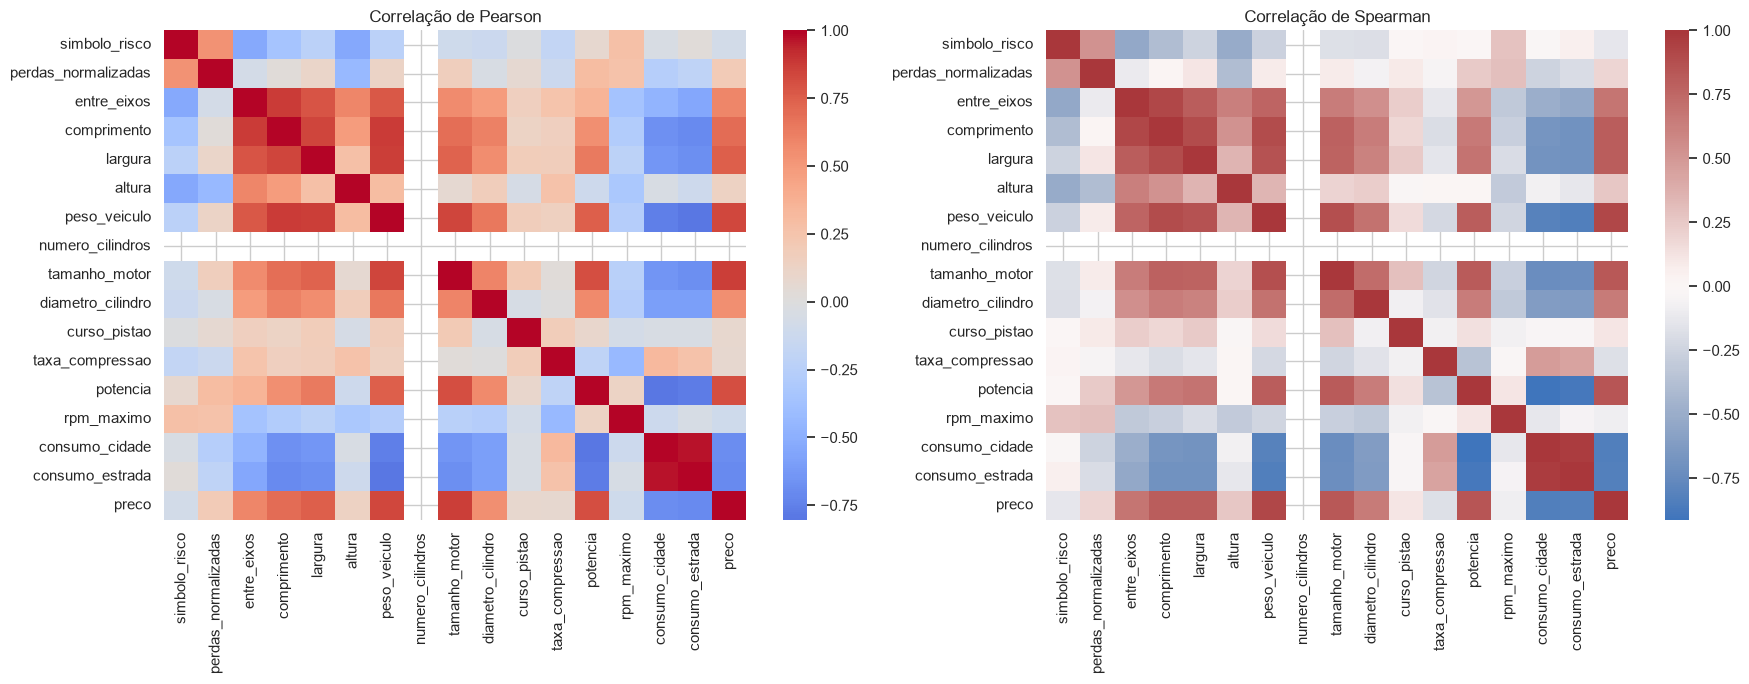

Pares com maior correlação absoluta de Pearson:


,,correlacao_pearson
consumo_cidade,consumo_estrada,0.971337
comprimento,peso_veiculo,0.877728
entre_eixos,comprimento,0.874587
tamanho_motor,preco,0.872335
largura,peso_veiculo,0.867032
peso_veiculo,tamanho_motor,0.850594
comprimento,largura,0.841118
peso_veiculo,preco,0.834415
tamanho_motor,potencia,0.810773
potencia,preco,0.810533


In [11]:
numericas_para_corr = database.select_dtypes(include=np.number)
corr_pearson = numericas_para_corr.corr(method="pearson")
corr_spearman = numericas_para_corr.corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sns.heatmap(corr_pearson, cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Correlação de Pearson")
sns.heatmap(corr_spearman, cmap="vlag", center=0, ax=axes[1])
axes[1].set_title("Correlação de Spearman")
plt.tight_layout()
plt.show()

# Lista os pares com maior correlação absoluta, sem contar a diagonal nem duplicar pares.
pares = corr_pearson.where(np.triu(np.ones(corr_pearson.shape), k=1).astype(bool)).stack()
pares = pares.reindex(pares.abs().sort_values(ascending=False).index)
print("Pares com maior correlação absoluta de Pearson:")
display(pares.head(10).rename("correlacao_pearson").to_frame())

### Associação entre atributos categóricos — Crosstab

A tabulação cruzada permite comparar frequências entre duas variáveis categóricas. Aqui, comparamos tipo de combustível e número de portas.

numero_portas,four,two,NaN,All
tipo_combustivel,,,,
diesel,16,3,1,20
gas,98,86,1,185
All,114,89,2,205


numero_portas,four,two
tipo_combustivel,,
diesel,84.2%,15.8%
gas,53.3%,46.7%


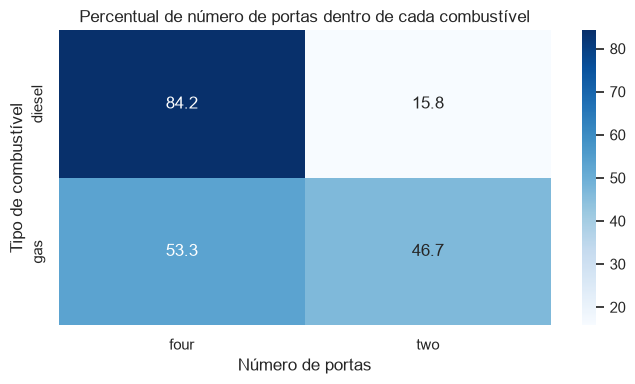

In [12]:
crosstab_cat = pd.crosstab(
    database["tipo_combustivel"],
    database["numero_portas"],
    margins=True,
    dropna=False
)
display(crosstab_cat)

crosstab_percentual = pd.crosstab(
    database["tipo_combustivel"],
    database["numero_portas"],
    normalize="index"
) * 100
display(crosstab_percentual.round(2).style.format("{:.1f}%"))

plt.figure(figsize=(7, 4))
sns.heatmap(crosstab_percentual, annot=True, fmt=".1f", cmap="Blues")
plt.title("Percentual de número de portas dentro de cada combustível")
plt.xlabel("Número de portas")
plt.ylabel("Tipo de combustível")
plt.tight_layout()
plt.show()

### Conclusão sobre correlações

Compare os pares mais correlacionados e confira se a relação faz sentido no contexto dos automóveis. Correlações elevadas entre dimensões ou peso podem refletir características físicas relacionadas; uma associação entre preço e potência pode indicar que veículos mais potentes tendem a custar mais, mas a conclusão deve ser confirmada pelos coeficientes observados. A crosstab descreve proporções, não causalidade.

## 5. Histogramas, assimetria e Power Transformation

Será plotado um histograma para cada atributo numérico. A assimetria (*skewness*) próxima de zero indica distribuição aproximadamente simétrica; valores positivos indicam cauda à direita e valores negativos indicam cauda à esquerda. A transformação Yeo-Johnson aceita valores zero e negativos. Para lidar com valores ausentes, a transformação usa imputação pela mediana apenas nesta etapa.

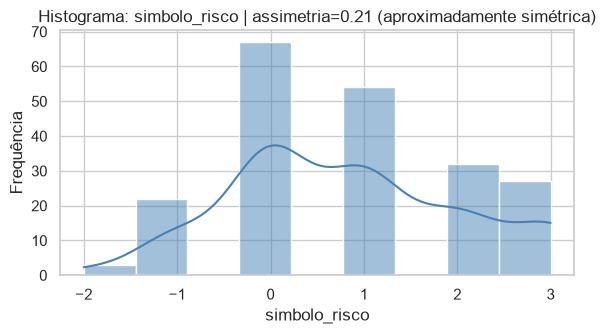

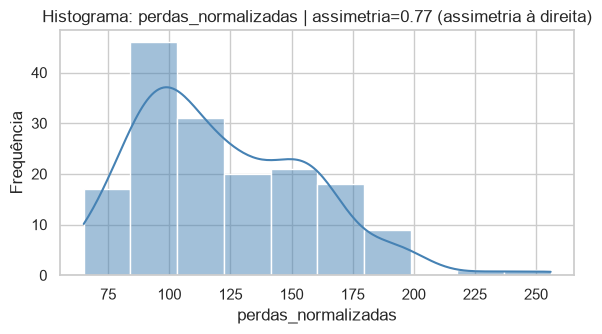

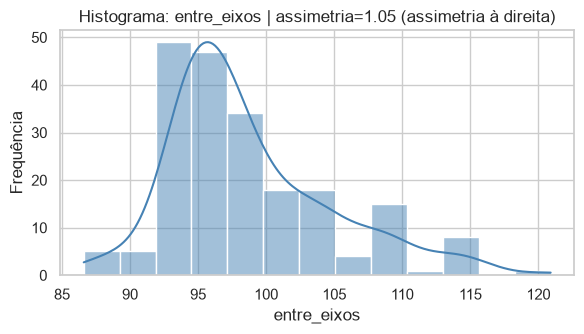

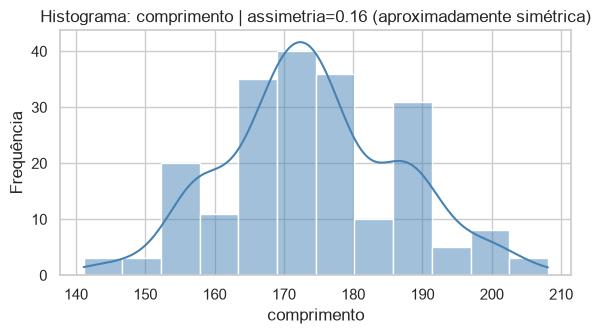

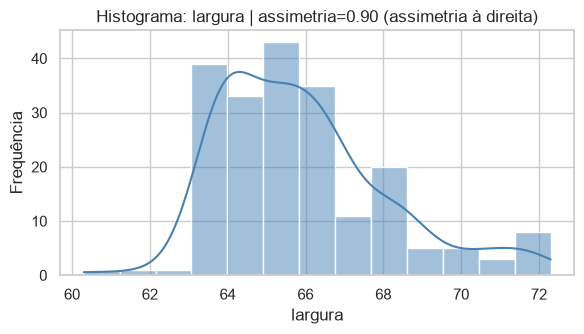

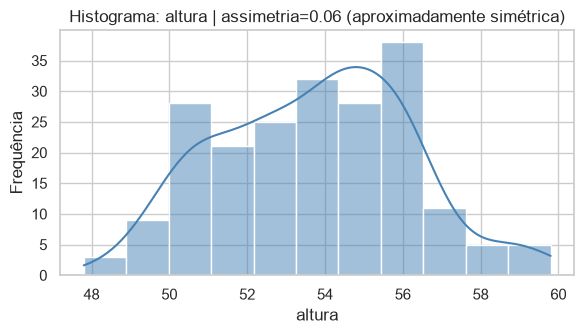

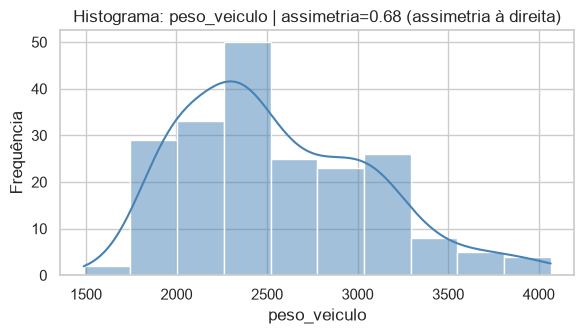

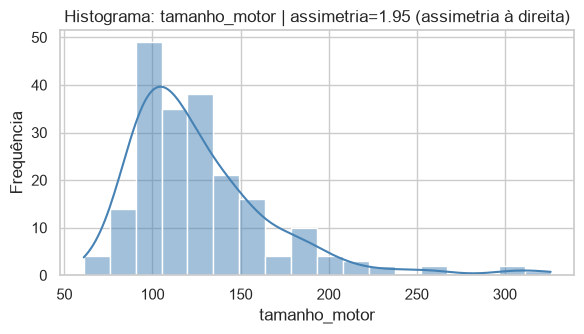

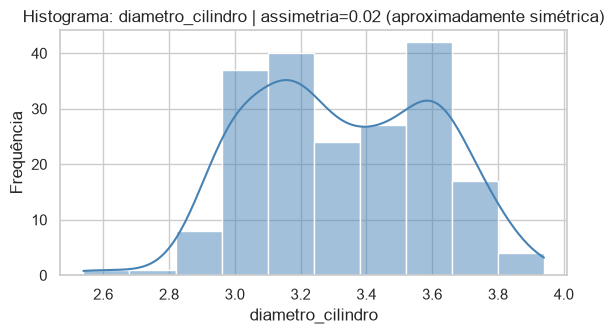

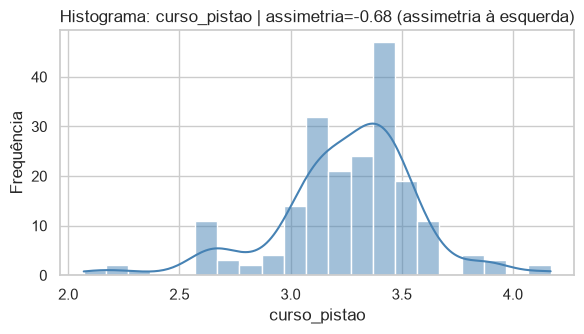

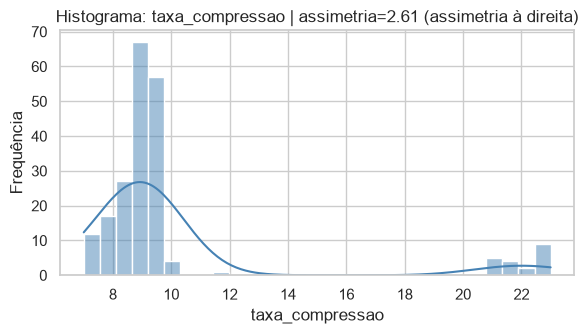

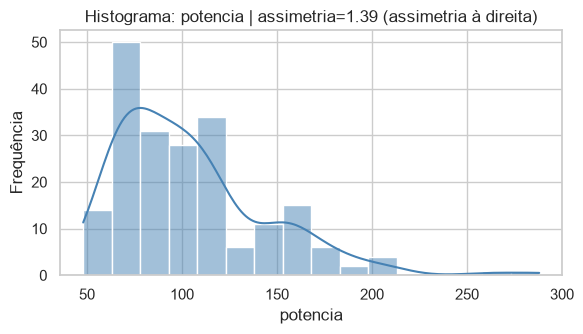

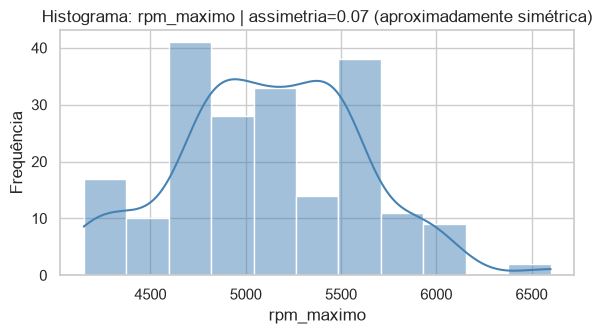

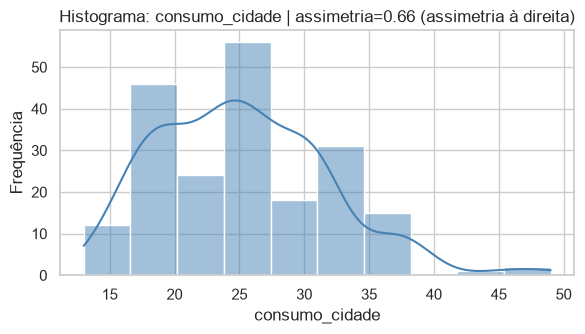

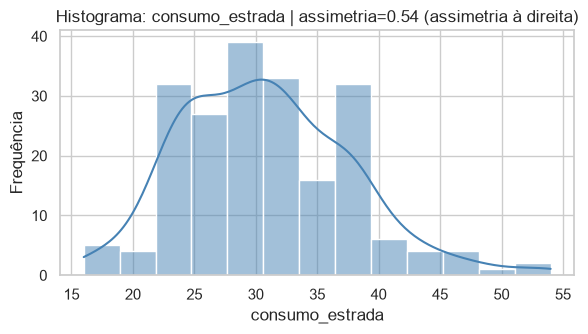

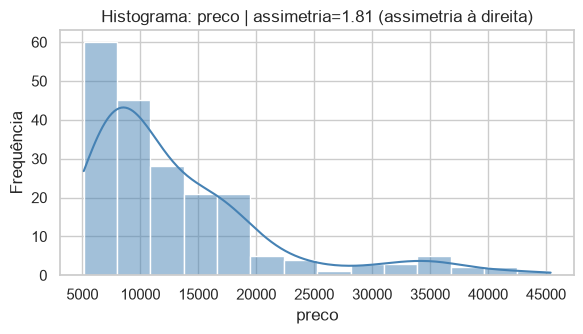

In [13]:
for coluna in colunas_numericas:
    serie = database[coluna].dropna()
    if serie.empty:
        continue
    assimetria = serie.skew()
    if assimetria > 0.5:
        interpretacao = "assimetria à direita"
    elif assimetria < -0.5:
        interpretacao = "assimetria à esquerda"
    else:
        interpretacao = "aproximadamente simétrica"
    plt.figure(figsize=(6, 3.5))
    sns.histplot(serie, kde=True, color="steelblue")
    plt.title(f"Histograma: {coluna} | assimetria={assimetria:.2f} ({interpretacao})")
    plt.xlabel(coluna)
    plt.ylabel("Frequência")
    plt.tight_layout()
    plt.show()

In [14]:
# Compara a assimetria antes e depois da transformação Yeo-Johnson.
# Excluímos colunas totalmente vazias e colunas constantes, que não podem ser transformadas.
colunas_transformaveis = [
    c for c in colunas_numericas
    if database[c].notna().sum() > 1 and database[c].nunique(dropna=True) > 1
]
dados_imputados = database[colunas_transformaveis].copy()
for coluna in colunas_transformaveis:
    dados_imputados[coluna] = dados_imputados[coluna].fillna(dados_imputados[coluna].median())

pt = PowerTransformer(method="yeo-johnson", standardize=True)
dados_transformados = pd.DataFrame(
    pt.fit_transform(dados_imputados),
    columns=colunas_transformaveis,
    index=dados_imputados.index
)

comparacao_assimetria = pd.DataFrame({
    "assimetria_original": database[colunas_transformaveis].skew(),
    "assimetria_transformada": dados_transformados.skew()
})
comparacao_assimetria["abs_assimetria_original"] = comparacao_assimetria["assimetria_original"].abs()
comparacao_assimetria["abs_assimetria_transformada"] = comparacao_assimetria["assimetria_transformada"].abs()
comparacao_assimetria["melhorou_em_assimetria"] = (
    comparacao_assimetria["abs_assimetria_transformada"] <
    comparacao_assimetria["abs_assimetria_original"]
)
display(comparacao_assimetria.round(3))

melhoraram = int(comparacao_assimetria["melhorou_em_assimetria"].sum())
print(f"A assimetria absoluta diminuiu em {melhoraram} de {len(comparacao_assimetria)} atributos transformados.")
print("A transformação pode reduzir assimetria, mas não garante normalidade para todas as variáveis.")

,assimetria_original,assimetria_transformada,abs_assimetria_original,abs_assimetria_transformada,melhorou_em_assimetria
simbolo_risco,0.211,-0.065,0.211,0.065,True
perdas_normalizadas,0.766,0.000,0.766,0.000,True
entre_eixos,1.050,-0.004,1.050,0.004,True
comprimento,0.156,-0.000,0.156,0.000,True
largura,0.904,-8.144,0.904,8.144,False
altura,0.063,-0.003,0.063,0.003,True
peso_veiculo,0.681,0.025,0.681,0.025,True
tamanho_motor,1.948,-0.003,1.948,0.003,True
diametro_cilindro,0.020,-0.011,0.020,0.011,True
curso_pistao,-0.683,0.113,0.683,0.113,True


A assimetria absoluta diminuiu em 15 de 16 atributos transformados.
A transformação pode reduzir assimetria, mas não garante normalidade para todas as variáveis.


## 6. Boxplots e possíveis outliers

Os boxplots são apresentados para todos os atributos numéricos. Como as escalas são diferentes, o gráfico conjunto ajuda a visualizar o panorama, mas dificulta comparar variáveis. A tabela usa a regra do intervalo interquartil (IQR): valores abaixo de Q1 − 1,5×IQR ou acima de Q3 + 1,5×IQR são sinalizados como possíveis outliers. Isso não significa automaticamente que sejam erros.

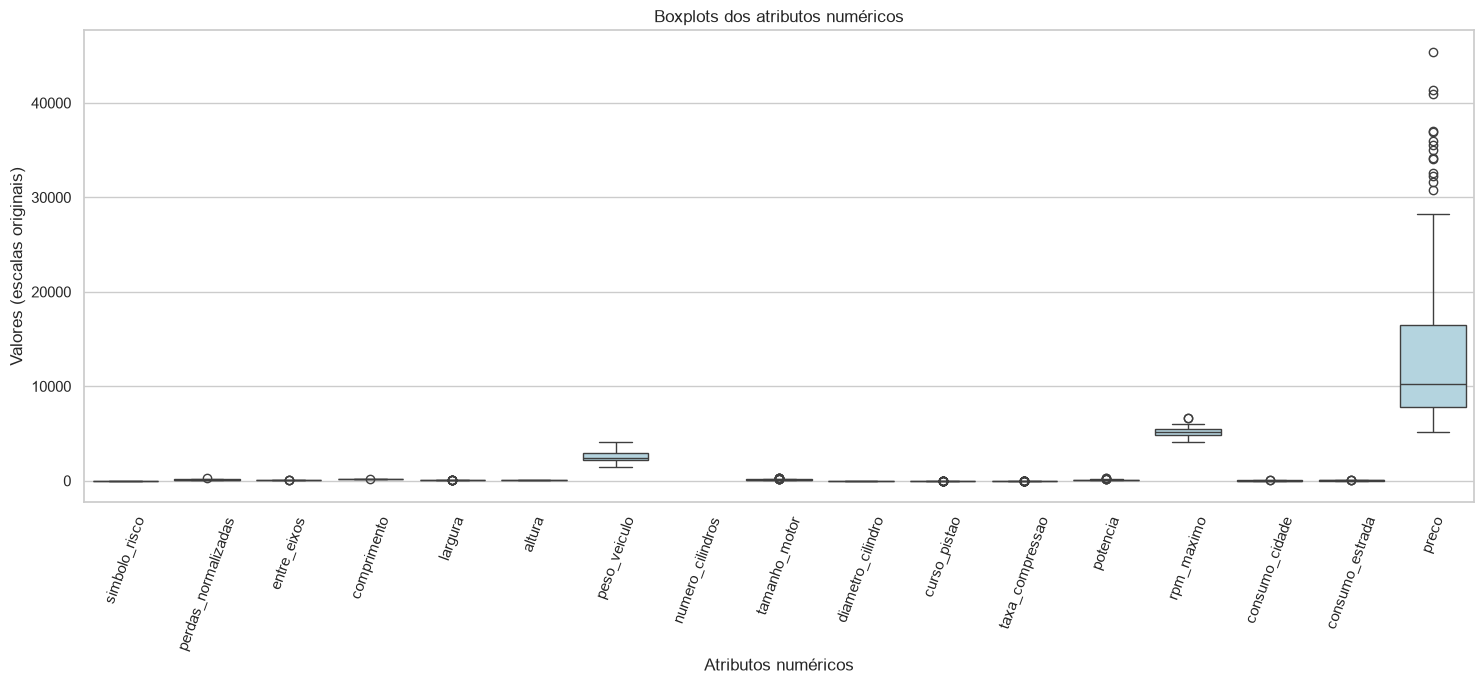

,atributo,limite_inferior,limite_superior,possiveis_outliers
10,taxa_compressao,7.40,10.60,28
9,curso_pistao,2.66,3.86,20
15,preco,-5312.50,29587.50,14
7,tamanho_motor,31.00,207.00,10
4,largura,59.90,71.10,8
11,potencia,1.00,185.00,6
2,entre_eixos,82.65,114.25,3
14,consumo_estrada,11.50,47.50,3
12,rpm_maximo,3750.00,6550.00,2
13,consumo_cidade,2.50,46.50,2


In [15]:
plt.figure(figsize=(15, 7))
sns.boxplot(data=database[colunas_numericas], color="lightblue")
plt.title("Boxplots dos atributos numéricos")
plt.xlabel("Atributos numéricos")
plt.ylabel("Valores (escalas originais)")
plt.xticks(rotation=70)
plt.tight_layout()
plt.show()

linhas_outliers = []
for coluna in colunas_numericas:
    serie = database[coluna].dropna()
    if serie.empty:
        continue
    q1_col = serie.quantile(0.25)
    q3_col = serie.quantile(0.75)
    iqr = q3_col - q1_col
    limite_inferior = q1_col - 1.5 * iqr
    limite_superior = q3_col + 1.5 * iqr
    quantidade = int(((serie < limite_inferior) | (serie > limite_superior)).sum())
    linhas_outliers.append({
        "atributo": coluna,
        "limite_inferior": limite_inferior,
        "limite_superior": limite_superior,
        "possiveis_outliers": quantidade
    })

tabela_outliers = pd.DataFrame(linhas_outliers).sort_values("possiveis_outliers", ascending=False)
display(tabela_outliers.round(2))

### Interpretação dos outliers

A tabela mostra em quais atributos a regra do IQR identifica mais valores extremos. Esses registros devem ser investigados no contexto da variável. Em uma base de automóveis, preços ou potências muito altos podem representar modelos realmente diferenciados, e não erros de preenchimento.

## 7. Gráficos exigidos no enunciado

A seguir são apresentados pelo menos um scatter plot, um gráfico de linhas, um gráfico de barras e um heatmap. Cada gráfico possui título e rótulos nos eixos.

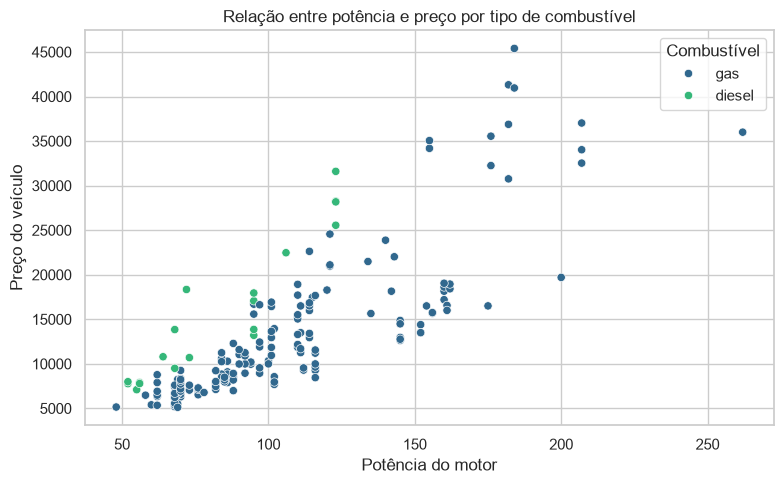

In [16]:
# Scatter: preço e potência, diferenciados pelo combustível.
plt.figure(figsize=(8, 5))
sns.scatterplot(data=database, x="potencia", y="preco", hue="tipo_combustivel", palette="viridis")
plt.title("Relação entre potência e preço por tipo de combustível")
plt.xlabel("Potência do motor")
plt.ylabel("Preço do veículo")
plt.legend(title="Combustível")
plt.tight_layout()
plt.show()

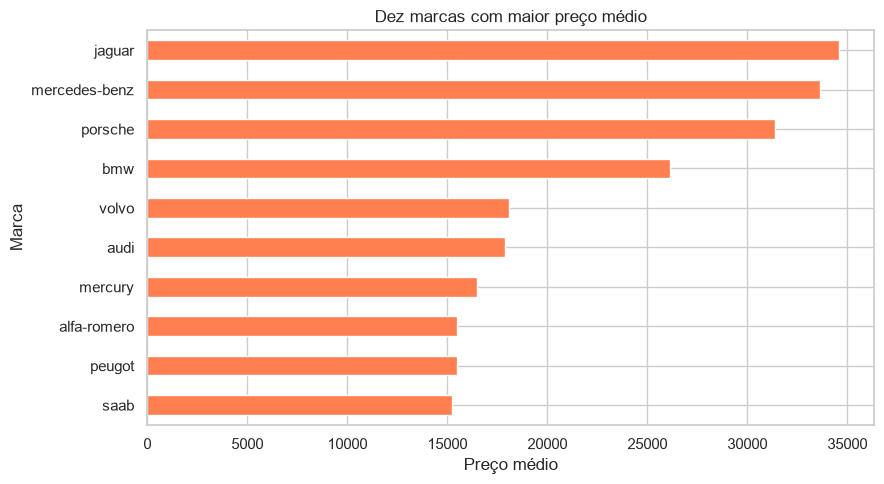

In [17]:
# Barras: preço médio por marca, mostrando as 10 marcas com maior preço médio.
preco_medio_marca = (
    database.groupby("marca", dropna=True)["preco"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)
plt.figure(figsize=(9, 5))
preco_medio_marca.plot(kind="barh", color="coral")
plt.title("Dez marcas com maior preço médio")
plt.xlabel("Preço médio")
plt.ylabel("Marca")
plt.tight_layout()
plt.show()

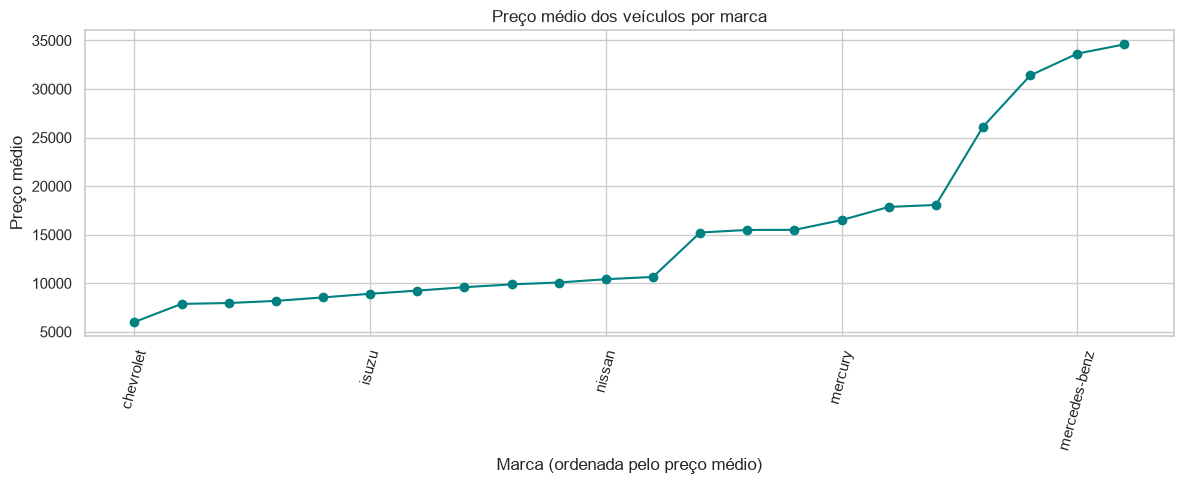

In [18]:
# Linhas: preço médio por marca, ordenado pelo preço médio.
preco_medio_marca_linha = (
    database.groupby("marca", dropna=True)["preco"]
    .mean()
    .sort_values()
)
plt.figure(figsize=(12, 5))
preco_medio_marca_linha.plot(kind="line", marker="o", color="teal")
plt.title("Preço médio dos veículos por marca")
plt.xlabel("Marca (ordenada pelo preço médio)")
plt.ylabel("Preço médio")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

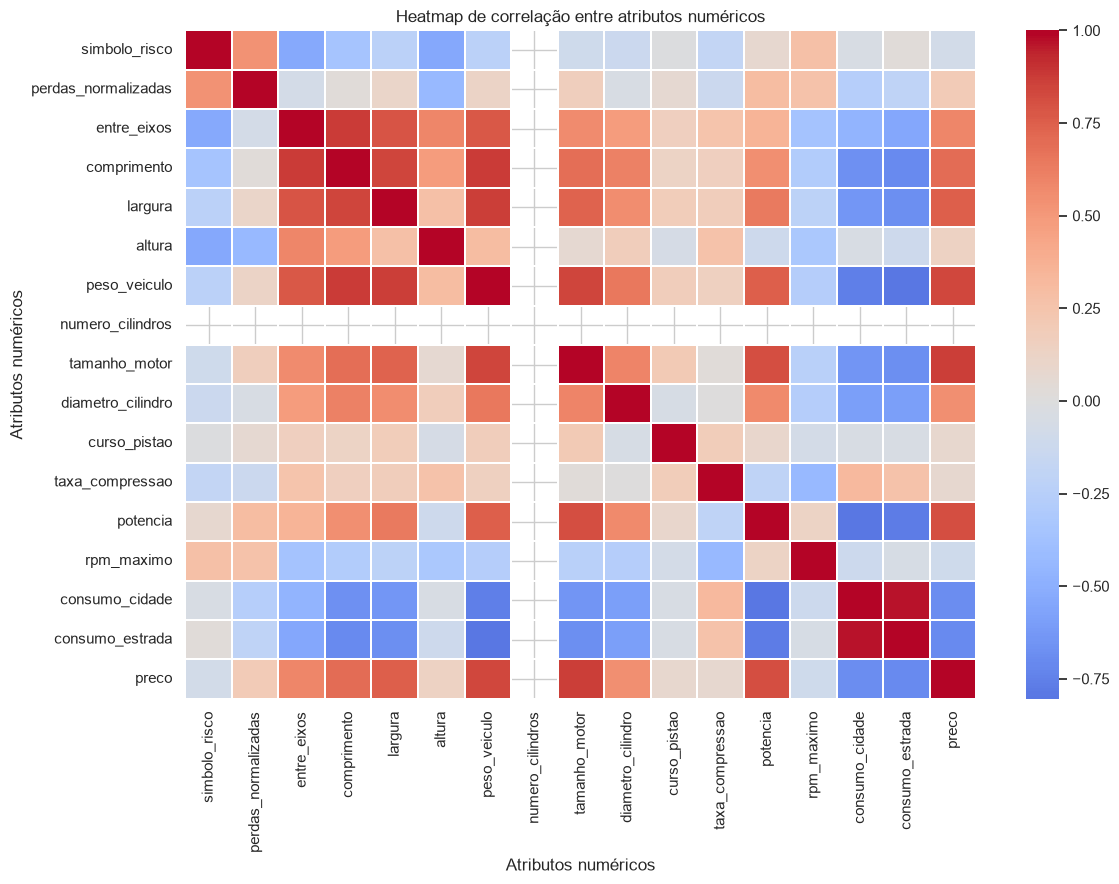

In [19]:
# Heatmap: correlação de Pearson entre os atributos numéricos.
plt.figure(figsize=(12, 9))
sns.heatmap(corr_pearson, cmap="coolwarm", center=0, annot=False, linewidths=0.2)
plt.title("Heatmap de correlação entre atributos numéricos")
plt.xlabel("Atributos numéricos")
plt.ylabel("Atributos numéricos")
plt.tight_layout()
plt.show()

## 8. Conclusão geral

Após executar todas as células, a análise deve ser concluída com base nos resultados reais observados. A base permite estudar a composição dos veículos, a dispersão de preços e características técnicas, além de investigar associações entre potência, peso, dimensões, consumo e preço. As consultas booleanas ajudam a identificar grupos específicos; correlações e gráficos mostram padrões e possíveis valores extremos. Os resultados são descritivos e não demonstram causalidade.

**Pontos a registrar na apresentação:**
1. Quais atributos possuem mais valores ausentes e como isso foi tratado.
2. Quais variáveis apresentam maior dispersão ou assimetria.
3. Quais pares numéricos apresentam correlação mais forte.
4. O que a comparação por combustível e número de portas revela.
5. Se a Power Transformation reduziu a assimetria e em quais atributos.
6. Quais possíveis outliers parecem representar veículos incomuns, e não necessariamente erros.